In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import ast
import seaborn as sns

df = pd.read_csv('data_jobs.csv')

df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

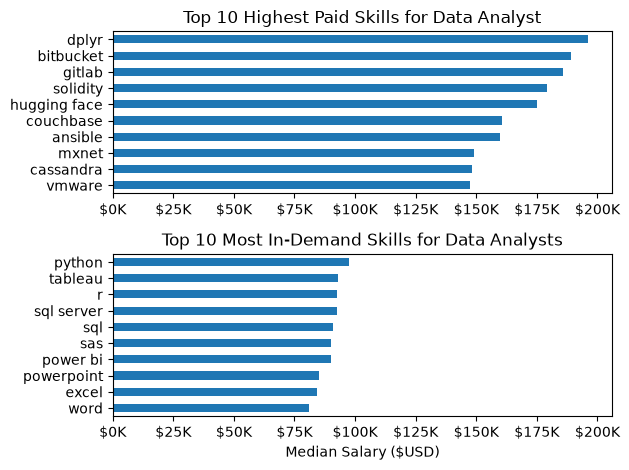

In [3]:
df_DA_US = df[(df['job_title_short'] == 'Data Analyst') & (df['job_country'] == 'United States')].copy()
df_DA_US = df_DA_US.dropna(subset=['salary_year_avg'])
df_DA_US = df_DA_US.explode('job_skills')
df_DA_US[['salary_year_avg', 'job_skills']]

df_DA_US_group  = df_DA_US.groupby('job_skills')['salary_year_avg'].agg(['count', 'median'])
df_DA_top_pay = df_DA_US_group.sort_values(by='median', ascending=False).head(10)
df_DA_skills = df_DA_US_group.sort_values(by='count', ascending=False).head(10).sort_values(by='median', ascending=False)

fig, ax = plt.subplots(2, 1)

df_DA_top_pay.plot(kind='barh', y='median', ax=ax[0], legend=False)
ax[0].invert_yaxis()
ax[0].set_title('Top 10 Highest Paid Skills for Data Analyst')
ax[0].set_ylabel('')
ax[0].set_xlabel('')
ax[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, __: f'${int(x/1000)}K'))

df_DA_skills[::-1].plot(kind='barh', y='median', ax=ax[1], legend=False)
ax[1].set_xlim(ax[0].get_xlim())
ax[1].set_ylabel('')
ax[1].set_title('Top 10 Most In-Demand Skills for Data Analysts')
ax[1].set_xlabel('Median Salary ($USD)')
ax[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, __: f'${int(x/1000)}K'))

fig.tight_layout()

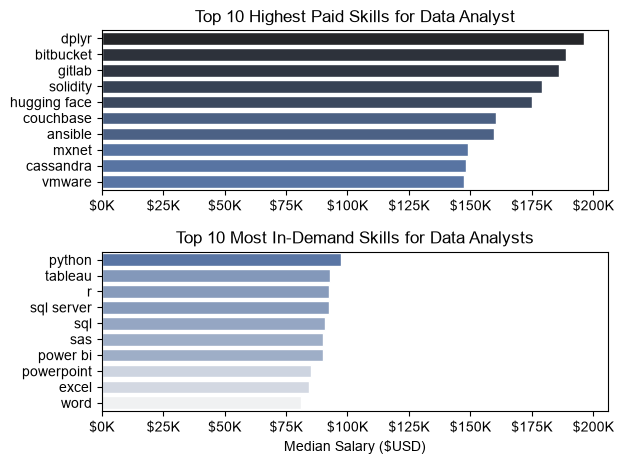

In [4]:
fig, ax = plt.subplots(2, 1)

sns.set_theme(style='ticks')
#df_DA_top_pay.plot(kind='barh', y='median', ax=ax[0], legend=False)
sns.barplot(data=df_DA_top_pay, x='median', y=df_DA_top_pay.index, ax=ax[0], hue='median', palette='dark:b_r')

ax[0].set_title('Top 10 Highest Paid Skills for Data Analyst')
ax[0].legend().remove()
ax[0].set_ylabel('')
ax[0].set_xlabel('')
ax[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, __: f'${int(x/1000)}K'))

#df_DA_skills[::-1].plot(kind='barh', y='median', ax=ax[1], legend=False)
sns.barplot(data=df_DA_skills, x='median', y=df_DA_skills.index, ax=ax[1], hue='median', palette='light:b')

ax[1].set_xlim(ax[0].get_xlim())
ax[1].set_ylabel('')
ax[1].set_title('Top 10 Most In-Demand Skills for Data Analysts')
ax[1].legend().remove()
ax[1].set_xlabel('Median Salary ($USD)')
ax[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, __: f'${int(x/1000)}K'))

fig.tight_layout()

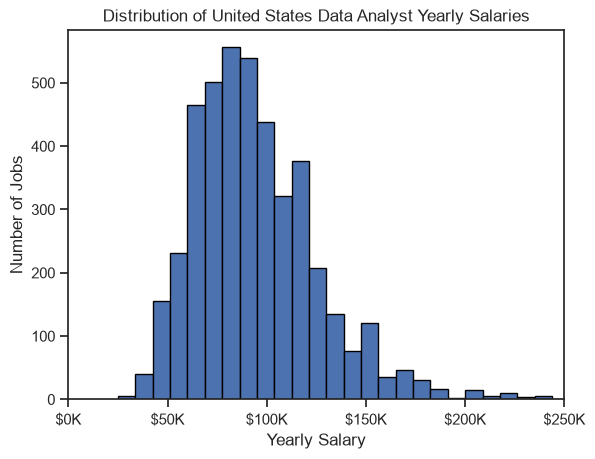

In [5]:
df_DA_US = df[(df['job_title_short'] == 'Data Analyst') & (df['job_country'] == 'United States')].copy()
df_DA_US['salary_year_avg'].plot(kind='hist', bins=40, edgecolor='black')
plt.xlim(0, 250000)

ax=plt.gca()
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${int(x/1000)}K'))

plt.title('Distribution of United States Data Analyst Yearly Salaries')
plt.xlabel('Yearly Salary')
plt.ylabel('Number of Jobs')
plt.show()

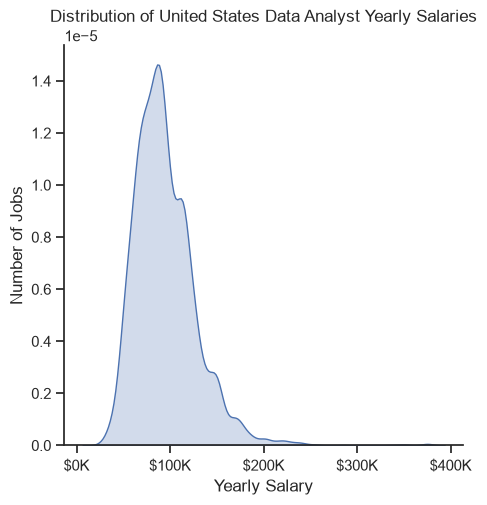

In [6]:
df_DA_US = df[(df['job_title_short'] == 'Data Analyst') & (df['job_country'] == 'United States')].copy()

sns.displot(df_DA_US['salary_year_avg'], kind='kde', fill=True)

#plt.xlim(0, 250000)

ax=plt.gca()
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${int(x/1000)}K'))

plt.title('Distribution of United States Data Analyst Yearly Salaries')
plt.xlabel('Yearly Salary')
plt.ylabel('Number of Jobs')
plt.show()

C:\Users\Youssef.Louca\AppData\Local\Temp\ipykernel_23480\3520496202.py:11: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(job_list, tick_labels=job_titles, vert=False)


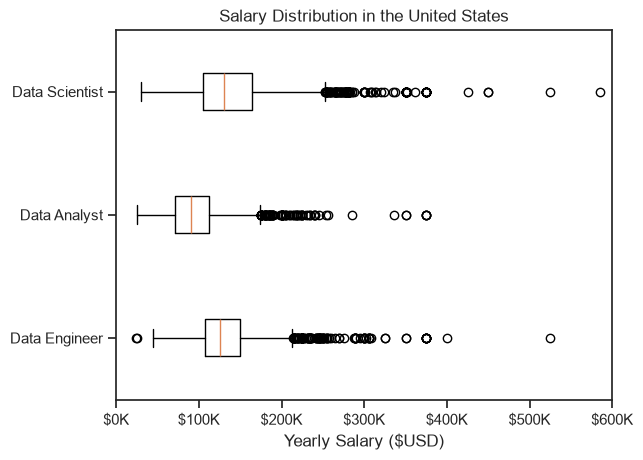

In [7]:
df_DA_US = df[(df['job_title_short'] == 'Data Analyst') & (df['job_country'] == 'United States')].copy()
df_DA_US = df_DA_US.dropna(subset=['salary_year_avg'])

job_titles = ['Data Engineer', 'Data Analyst', 'Data Scientist']
df_US = df[(df['job_title_short'].isin(job_titles)) & (df['job_country'] == 'United States')].copy()

df_US = df_US.dropna(subset=['salary_year_avg'])

job_list = [df_US[df_US['job_title_short'] == job_title]['salary_year_avg'] for job_title in job_titles]

plt.boxplot(job_list, tick_labels=job_titles, vert=False)
plt.title('Salary Distribution in the United States')
plt.xlabel('Yearly Salary ($USD)')
ax = plt.gca()
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, pos: f'${int(x/1000)}K'))
plt.xlim(0, 600000)
plt.show()

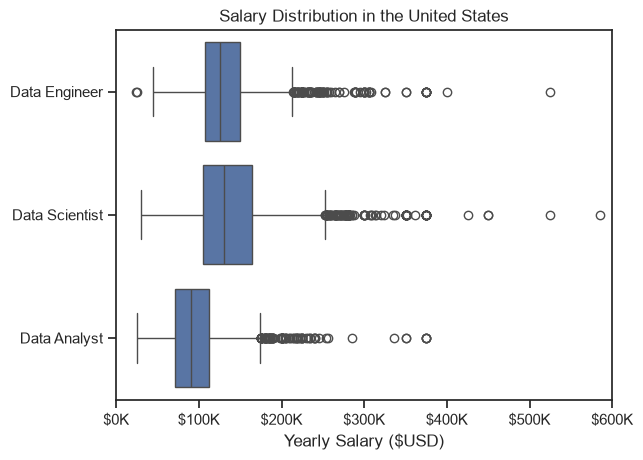

In [8]:
sns.boxplot(data=df_US, x='salary_year_avg', y='job_title_short')

plt.title('Salary Distribution in the United States')
plt.xlabel('Yearly Salary ($USD)')
plt.ylabel('')
ax = plt.gca()
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, pos: f'${int(x/1000)}K'))
plt.xlim(0, 600000)
plt.show()

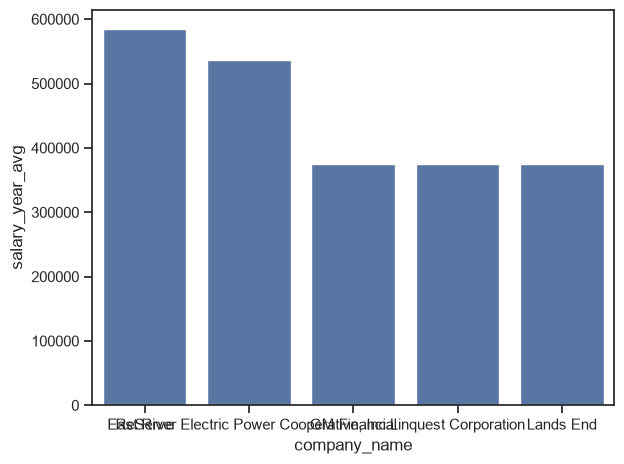

In [9]:
df_DS = df[df['job_title_short'] == 'Data Scientist'].copy()
df_DS = df_DS.dropna(subset=['salary_year_avg'])

df_DS = df_DS.groupby('company_name')['salary_year_avg'].median().sort_values(ascending=False).head(5)

sns.barplot(df_DS)
plt.tight_layout()
plt.show()

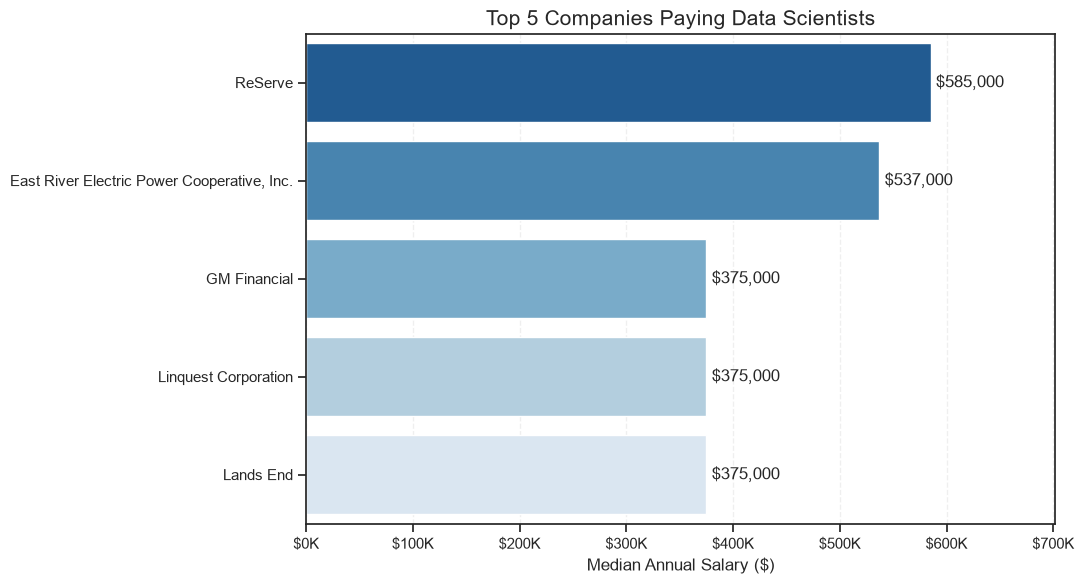

In [16]:
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

df_DS = df[df['job_title_short'] == 'Data Scientist'].copy()
df_DS = df_DS.dropna(subset=['salary_year_avg'])

df_DS = (
    df_DS.groupby('company_name')['salary_year_avg']
    .median()
    .sort_values(ascending=False)
    .head(5)
    .reset_index()
)

plt.figure(figsize=(11, 6))
colors = sns.color_palette('Blues_r', n_colors=5)
ax = sns.barplot(
    data=df_DS,
    x='salary_year_avg',
    y='company_name',
    hue='company_name',
    palette=colors,
    legend=False
)

# Format x-axis as dollars
ax.xaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f'${x/1000:.0f}K')
)

# Add salary labels to each bar
for bar in ax.patches:
    width = bar.get_width()

    if width > 0:
        ax.text(
            width + 5000,
            bar.get_y() + bar.get_height() / 2,
            f'${width:,.0f}',
            va='center'
        )

plt.xlim(0, df_DS['salary_year_avg'].max() * 1.2)

plt.xlabel('Median Annual Salary ($)')
plt.ylabel('')
plt.title('Top 5 Companies Paying Data Scientists', fontsize=15)

plt.grid(axis='x', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

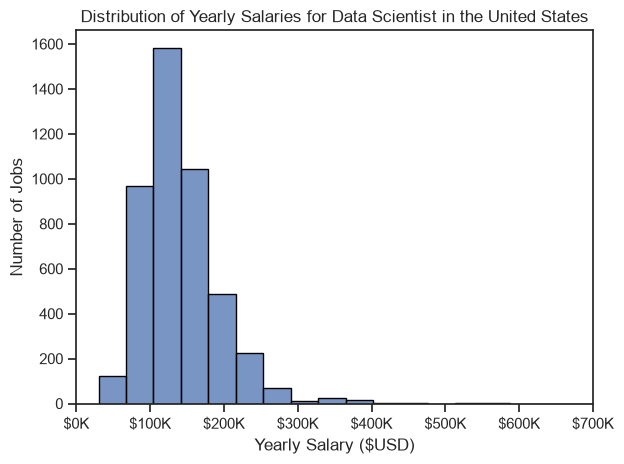

In [32]:
df_DS = df[(df['job_title_short'] == 'Data Scientist') & (df['job_country'] == 'United States')].copy()
df_DS = df_DS.dropna(subset=['salary_year_avg'])

sns.histplot(df_DS['salary_year_avg'], bins=25, kde=False, edgecolor='black')
ax=plt.gca()
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, pos: f'${int(x/1000)}K'))

plt.xlim(0,700000)
plt.title('Distribution of Yearly Salaries for Data Scientist in the United States')
plt.ylabel('Number of Jobs')
plt.xlabel('Yearly Salary ($USD)')
plt.tight_layout()
plt.show()

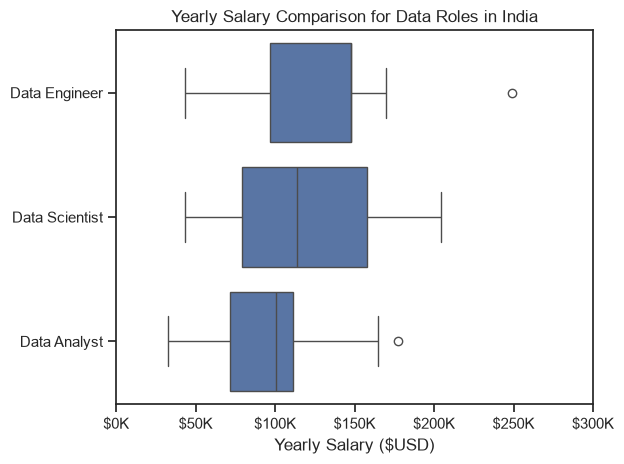

In [38]:
job_titles = ['Data Analyst', 'Data Engineer', 'Data Scientist']
df_IN = df[(df['job_country'] == 'India') & (df['job_title_short'].isin(job_titles))].dropna(subset=['salary_year_avg']).copy()

sns.boxplot(data=df_IN, x='salary_year_avg', y='job_title_short')
plt.xlim(0, 300_000)
ax = plt.gca()
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, pos: f'${int(x/1000)}K'))
plt.title('Yearly Salary Comparison for Data Roles in India')
plt.xlabel('Yearly Salary ($USD)')
plt.ylabel('')
plt.tight_layout()
plt.show()

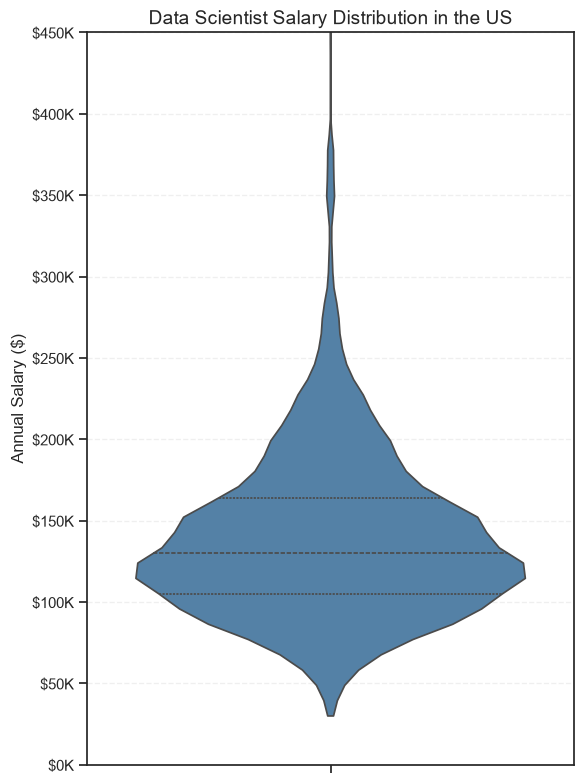

In [48]:
df_DS = df[(df['job_title_short'] == 'Data Scientist') & (df['job_country'] == 'United States')].dropna(subset=['salary_year_avg']).copy()

plt.figure(figsize=(6, 8))

ax = sns.violinplot(
    data=df_DS,
    y='salary_year_avg',
    color='steelblue',
    inner='quart',
    cut=0
)

# Format y-axis as dollars
ax.yaxis.set_major_formatter(
    FuncFormatter(lambda y, pos: f'${y/1000:.0f}K')
)

plt.title('Data Scientist Salary Distribution in the US', fontsize=14)
plt.ylabel('Annual Salary ($)')
plt.xlabel('')
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.ylim(0, 450000)

plt.tight_layout()
plt.show()